In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as spc

from libOctopusIO import store_transition_dipole, load_kpoints_data, extract_info
from libElectrical import get_conductivity, get_permittivity, \
                          plot_conductivity, load_epsilon_table

In [2]:
main_path = "./Si/"

---
### Conductivity

In [3]:
Eh_to_eV = spc.physical_constants["hartree-electron volt relationship"][0]

In [4]:
# To be run once
store_transition_dipole(os.path.join(main_path, "16x16x16", "static"))

In [5]:
small_delta = 0.2 # eV
large_delta = 0.2 # eV
n_decimals = 3
negative_contributions = True

In [6]:
k_main_path = os.path.join(main_path, "16x16x16")

kpoints_data = load_kpoints_data(output_path=k_main_path)
info_path = os.path.join(k_main_path, "static", "info")
band_path = os.path.join(k_main_path, "static", "bandstructure")
info_data = extract_info(info_path, band_path)

omega_16_large, conductivity_16_large = get_conductivity(kpoints_data, info_data, mode="KuboGreenwood", damping_parameter=large_delta/Eh_to_eV, round_to_decimals=n_decimals, negative_contributions=negative_contributions)

Text(0.5, 1.0, '$\\delta$ = 0.2 eV')

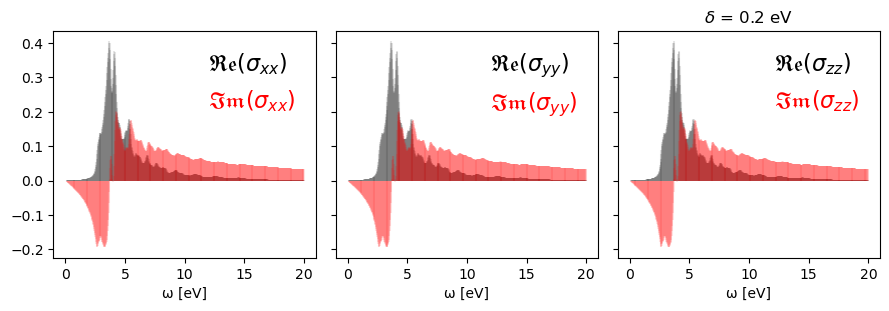

In [7]:
plot_conductivity(omega_16_large, conductivity_16_large, 20, diagonal_only=True, stem_alpha=0.1)
plt.title(f"$\delta$ = {large_delta} eV")

In [8]:
k_main_path = os.path.join(main_path, "24x24x24")

kpoints_data = load_kpoints_data(output_path=k_main_path)
info_path = os.path.join(k_main_path, "static", "info")
band_path = os.path.join(k_main_path, "static", "bandstructure")
info_data = extract_info(info_path, band_path)

omega_24_small, conductivity_24_small = get_conductivity(kpoints_data, info_data, mode="KuboGreenwood", damping_parameter=small_delta/Eh_to_eV, round_to_decimals=n_decimals, negative_contributions=negative_contributions)

Text(0.5, 1.0, '$\\delta$ = 0.2 eV')

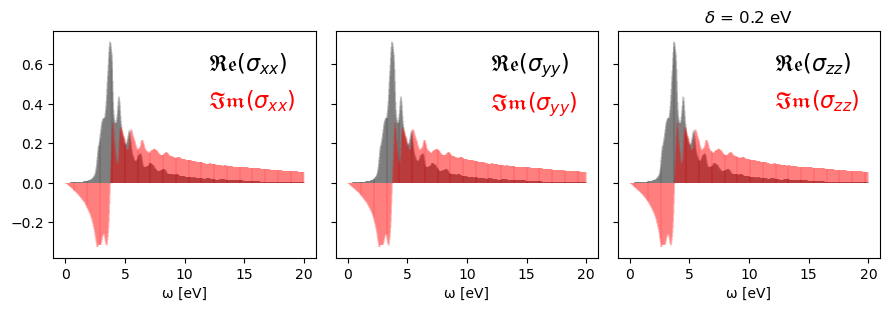

In [9]:
plot_conductivity(omega_24_small, conductivity_24_small, 20, diagonal_only=True, stem_alpha=0.1)
plt.title(f"$\delta$ = {small_delta} eV")

---
### Permittivity

In [10]:
epsilon_16_large = get_permittivity(omega_16_large, conductivity_16_large)
epsilon_24_small = get_permittivity(omega_24_small, conductivity_24_small)

/home/aibertoni/vault/main/Academia/Thibault/dipolar_matrix_elements/libElectrical.py:182: RuntimeWarning: invalid value encountered in true_divide
  epsilon = 1 + 1j * (conductivity/omega) * (4*np.pi)


In [11]:
exp_datafile = "Si-Palik"
exp_datapath = os.path.join(main_path, exp_datafile)
energy_exp, epsilon_exp = load_epsilon_table(exp_datapath)

si_tdlda_real = np.loadtxt(os.path.join(main_path, "Si-TDLDA-epsR.csv"))
si_tdlda_imag = np.loadtxt(os.path.join(main_path, "Si-TDLDA-epsC.csv"))

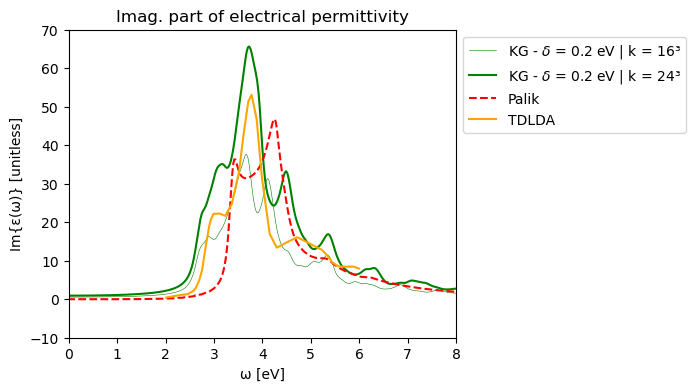

In [12]:
plt.figure(figsize=(5,4))

plt.plot(omega_16_large*Eh_to_eV, np.imag(epsilon_16_large), color="green", lw=0.4, label=f"KG - $\delta$ = {large_delta} eV | k = 16³")
plt.plot(omega_24_small*Eh_to_eV, np.imag(epsilon_24_small), color="green", label=f"KG - $\delta$ = {small_delta} eV | k = 24³")
plt.plot(energy_exp, np.imag(epsilon_exp), color="red", ls="dashed", label="Palik")

tdlda_grid, tdlda_imag = si_tdlda_imag.T
plt.plot(tdlda_grid, tdlda_imag, color="orange", label="TDLDA")

plt.xlim(0,8)
plt.ylim(-10,70)
plt.title("Imag. part of electrical permittivity")
plt.xlabel("ω [eV]")
plt.ylabel("Im{ε(ω)} [unitless]")
plt.legend(bbox_to_anchor=(1,1))

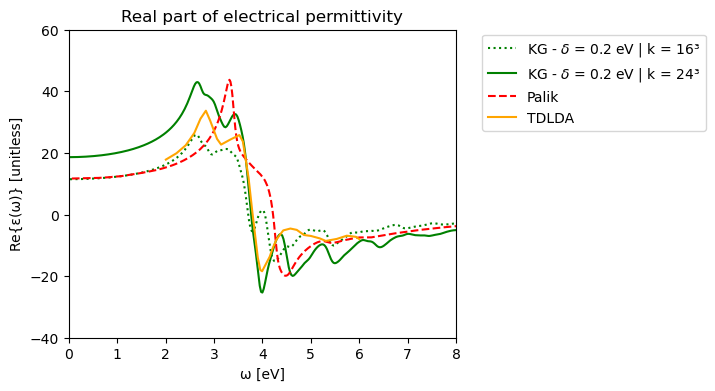

In [13]:
plt.figure(figsize=(5,4))

plt.plot(omega_16_large*Eh_to_eV, np.real(epsilon_16_large), color="green", ls="dotted", label=f"KG - $\delta$ = {large_delta} eV | k = 16³")
plt.plot(omega_24_small*Eh_to_eV, np.real(epsilon_24_small), color="green", label=f"KG - $\delta$ = {small_delta} eV | k = 24³")
plt.plot(energy_exp, np.real(epsilon_exp), color="red", ls="dashed", label="Palik")

tdlda_grid, tdlda_real = si_tdlda_real.T
plt.plot(tdlda_grid, tdlda_real, color="orange", label="TDLDA")

plt.xlim(0,8)
plt.ylim(-40,60)
plt.title("Real part of electrical permittivity")
plt.xlabel("ω [eV]")
plt.ylabel("Re{ε(ω)} [unitless]")
plt.legend(bbox_to_anchor=(1.05,0.65))

---

**Notebook by: Andrés Ignacio Bertoni 
(andresibertoni@gmail.com)**